# Beijing PM2.5: Exploratory Data Analysis

## 1. Introduction

This notebook explores hourly PM2.5 air pollution measurements in Beijing from 2010 to 2014, together with weather variables. The purpose is to understand the dataset, identify data-quality issues, investigate patterns in PM2.5 levels, and explore relationships that may be useful for time-series forecasting.

The analysis will investigate long-term trends, hourly patterns, relationships with weather conditions, lagged PM2.5 measurements, moving averages, and differences across wind directions. Each investigation will include the question being explored, the method used, a visualization, and an interpretation of the findings.

## 2. Dataset

The dataset is the Beijing PM2.5 Data dataset from the UCI Machine Learning Repository.

**Source:** https://archive.ics.uci.edu/dataset/381/beijing+pm2+5+data

The dataset contains hourly observations and includes the following information:

- **Date and time:** Year, month, day, and hour.
- **Target variable:** `pm2.5`, the measured fine particulate matter concentration.
- **Weather variables:** Dew point (`DEWP`), temperature (`TEMP`), atmospheric pressure (`PRES`), wind direction (`cbwd`), cumulative wind speed (`Iws`), and precipitation measurements (`Is` and `Ir`).

## 3. Analysis approach

We will begin by checking the dataset's dimensions, column types, missing values, date range, and timestamp consistency. We will then use exploratory data analysis to investigate at least five analytical questions.

Missing measurements will be examined before deciding how to handle them. We will not replace missing PM2.5 values with zero without justification, and we will distinguish observed findings from possible explanations.

Because this is time-series data, we will also examine chronological ordering and missing time intervals before calculating lagged features and moving averages. These checks will help us avoid misleading results and reduce the risk of data leakage.

## Step 1:Load and inspect the dataset

### Import libraries

In [2]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

### Locate and load the dataset

In [3]:
data_path = Path("../data/raw/PRSA_data_2010.1.1-2014.12.31.csv")

df = pd.read_csv(data_path, na_values=["NaN"])

print(f"Number of rows: {df.shape[0]:}")
print(f"Number of columns: {df.shape[1]}")

Number of rows: 43824
Number of columns: 13


### columns inspection and data quality

In [25]:
# preview the first 5 records

display(df.head())

,No,year,month,day,hour,pm2.5,DEWP,TEMP,PRES,cbwd,Iws,Is,Ir,timestamp
0,1,2010,1,1,0,NaN,-21,-11.0,1021.0,NW,1.79,0,0,2010-01-01 00:00:00
1,2,2010,1,1,1,NaN,-21,-12.0,1020.0,NW,4.92,0,0,2010-01-01 01:00:00
2,3,2010,1,1,2,NaN,-21,-11.0,1019.0,NW,6.71,0,0,2010-01-01 02:00:00
3,4,2010,1,1,3,NaN,-21,-14.0,1019.0,NW,9.84,0,0,2010-01-01 03:00:00
4,5,2010,1,1,4,NaN,-20,-12.0,1018.0,NW,12.97,0,0,2010-01-01 04:00:00


In [5]:
# inspect column names and data types

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 43824 entries, 0 to 43823
Data columns (total 13 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   No      43824 non-null  int64  
 1   year    43824 non-null  int64  
 2   month   43824 non-null  int64  
 3   day     43824 non-null  int64  
 4   hour    43824 non-null  int64  
 5   pm2.5   41757 non-null  float64
 6   DEWP    43824 non-null  int64  
 7   TEMP    43824 non-null  float64
 8   PRES    43824 non-null  float64
 9   cbwd    43824 non-null  str    
 10  Iws     43824 non-null  float64
 11  Is      43824 non-null  int64  
 12  Ir      43824 non-null  int64  
dtypes: float64(4), int64(8), str(1)
memory usage: 4.3 MB


In [8]:
# Count missing values in each column

print("missing_summary:", df.isna().sum())

missing_summary: No          0
year        0
month       0
day         0
hour        0
pm2.5    2067
DEWP        0
TEMP        0
PRES        0
cbwd        0
Iws         0
Is          0
Ir          0
dtype: int64


In [7]:
# Check for completely duplicated rows

print("Completely_duplicated_rows:", df.duplicated().sum())

Completely_duplicated_rows: 0


### Build timestamp and check time range

In [12]:
# Combine the date and hour column into a single timestamp

df["timestamp"] = pd.to_datetime(
    df[["day", "month", "year", "hour"]]
)

df =df.sort_values("timestamp").reset_index(drop=True)

print("First timestamp:", df["timestamp"].min())
print("Last timestamp:", df["timestamp"].max())

First timestamp: 2010-01-01 00:00:00
Last timestamp: 2014-12-31 23:00:00


In [22]:
# Check time difference between consecutive records

time_diff = df["timestamp"].diff().value_counts()

print("Most common time differences between records:")
display(time_diff)

Most common time differences between records:


timestamp
0 days 01:00:00    43823
Name: count, dtype: int64

### Analytical Question 1: How did PM2.5 levels change over time?

Question: How did the average PM2.5 concentration change from 2010 to 2014, and are there visible patterns across months?

Why this matters: Examining the monthly trend helps us understand how pollution levels vary over time. It may reveal longer-term changes or recurring seasonal patterns that could be useful when developing a time-series forecasting pipeline.

Method: We will calculate the mean PM2.5 concentration for each calendar month and visualize the results using a line chart. Pandas excludes missing PM2.5 values when calculating the mean, so each monthly average will be based on available measurements. We will also check how many valid measurements contribute to each monthly average.

In [23]:
# Calculate monthly PM2.5 averages and available measurements
monthly_pm25 = (
    df.set_index("timestamp")["pm2.5"]
    .resample("MS")
    .agg(["mean", "count"])
)

monthly_pm25.columns = ["mean_pm25", "valid_measurements"]

display(monthly_pm25.head())

,mean_pm25,valid_measurements
timestamp,,
2010-01-01,90.442573,653
2010-02-01,97.233979,671
2010-03-01,94.100141,709
2010-04-01,80.029248,718
2010-05-01,86.899593,737


In [26]:
# Summarize the number of valid measurements per month
print("Monthly valid measurement counts:")
display(monthly_pm25["valid_measurements"].describe())

Monthly valid measurement counts:


count     60.000000
mean     695.950000
std       56.094782
min      468.000000
25%      672.000000
50%      715.000000
75%      737.000000
max      744.000000
Name: valid_measurements, dtype: float64

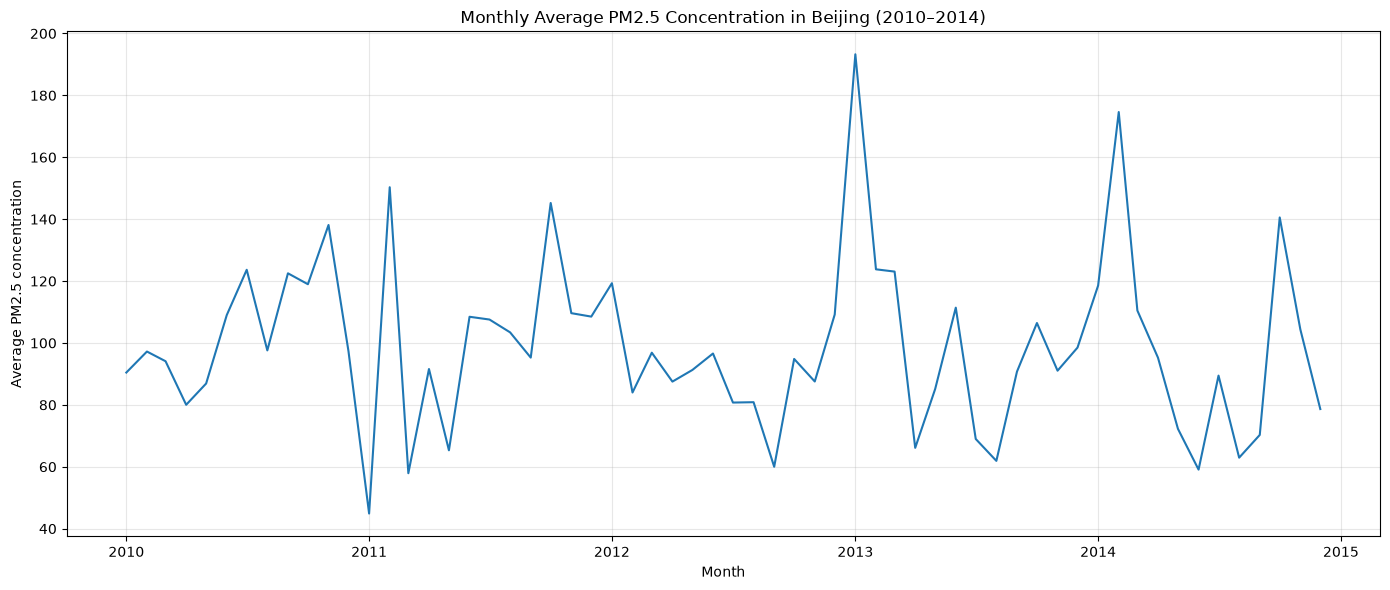

In [27]:
# Plot the monthly average PM2.5 concentration
plt.figure(figsize=(14, 6))

plt.plot(
    monthly_pm25.index,
    monthly_pm25["mean_pm25"],
    linewidth=1.5
)

plt.title("Monthly Average PM2.5 Concentration in Beijing (2010–2014)")
plt.xlabel("Month")
plt.ylabel("Average PM2.5 concentration")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The monthly average PM2.5 concentration fluctuates considerably between January 2010 and December 2014. Several months have average concentrations above 140, with the highest visible peak occurring in early 2013 at approximately 193. Other noticeable peaks appear in early 2011, late 2011, and early 2014.

The chart also contains periods with lower monthly averages, including some values between approximately 45 and 70. These changes suggest that PM2.5 concentrations vary substantially over time rather than remaining constant.

However, the visualization does not establish a consistent long-term increase or decrease, nor does it confirm a recurring seasonal pattern. Further analysis is needed to compare the same months across different years and investigate possible relationships with weather variables.

The monthly measurement counts also vary. There are 60 monthly averages, with a mean of approximately 696 valid measurements per month and a minimum of 468. Therefore, differences in data coverage should be considered when interpreting the monthly averages.

Conclusion: PM2.5 concentrations show substantial month-to-month variation, making temporal patterns an important area for further investigation. The next analysis will examine whether pollution levels differ by hour of the day.

### Analytical Question 2: Does PM2.5 vary by hour of the day?

Question: How does the average PM2.5 concentration change across the 24 hours of a day?

Why this matters: Hourly patterns may reveal recurring changes in pollution levels throughout the day. Identifying these patterns can help us decide whether the hour of the day should be included as a feature in a forecasting pipeline.

Method: We will group the available PM2.5 measurements by hour, calculate the mean for each hour from 0 to 23, and visualize the results using a line chart. We will also count the valid observations contributing to each hourly average.

In [28]:
# Calculate average PM2.5 concentration for each hour of the day
hourly_pm25 = (
    df.groupby("hour")["pm2.5"]
    .agg(["mean", "count"])
)

hourly_pm25.columns = ["mean_pm25", "valid_measurements"]

display(hourly_pm25)

,mean_pm25,valid_measurements
hour,,
0,113.390202,1735
1,113.698567,1745
2,110.323174,1739
3,108.042980,1745
4,104.080275,1744
5,100.013218,1740
6,96.882759,1740
7,96.024727,1739
8,95.907940,1738


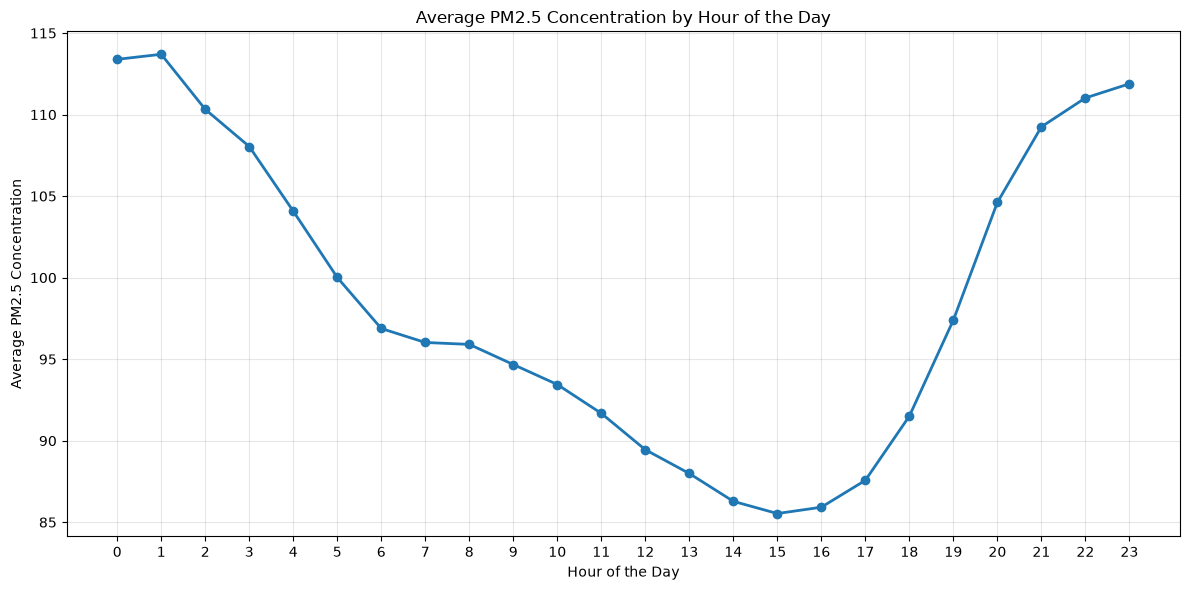

In [29]:
# Plot the average concentration by hour
plt.figure(figsize=(12, 6))

plt.plot(
    hourly_pm25.index,
    hourly_pm25["mean_pm25"],
    marker="o",
    linewidth=2
)

plt.title("Average PM2.5 Concentration by Hour of the Day")
plt.xlabel("Hour of the Day")
plt.ylabel("Average PM2.5 Concentration")
plt.xticks(range(24))
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

The average PM2.5 concentration varies noticeably by hour of the day. The highest hourly average occurs at 01:00, at approximately 113.70, followed closely by 00:00 at approximately 113.39. Concentrations generally decline during the morning and early afternoon, reaching their lowest average of approximately 85.53 at 15:00.

After 15:00, the average begins to rise. The increase becomes more pronounced during the evening, reaching approximately 104.61 at 20:00 and 111.89 at 23:00.

The difference between the highest and lowest hourly averages is approximately 28.16 concentration units. This suggests that the hour of the day may be a useful feature to investigate in a time-series forecasting pipeline.

These results describe average behavior across the full dataset. They do not establish that the same pattern occurs on every day or explain what causes the observed changes. Further analysis would be needed to investigate possible relationships with weather, season, and other factors.

Conclusion: The dataset exhibits a clear hourly pattern, with higher average PM2.5 concentrations late at night and lower averages during the afternoon.